# Punto 1: A quién revisar por abuso de bonos

## Objetivo del análisis

El objetivo de este análisis es proponer una estrategia que permita al equipo de Riesgo identificar usuarios con posibles comportamientos de abuso de bonos y priorizar las revisiones mensuales.

Actualmente, la selección se realiza mediante una regla fija: revisar a los usuarios que hayan reclamado tres o más bonos durante los últimos 30 días.

Buscamos desarrollar una alternativa basada en modelos de clasificación que permita mejorar la selección de usuarios, considerando las siguientes restricciones de negocio:

- Capacidad máxima de 600 revisiones mensuales.
- Coste de USD 4 por revisión.
- El monto de bonos reclamados por un usuario identificado como abusador representa el importe que se evita perder mediante su detección.

La evaluación tendrá en cuenta tanto el desempeño predictivo como el beneficio económico estimado frente a la regla actual.

## Importaciones y rutas
Se importan las librerías necesarias para la manipulación de datos, visualización, construcción de pipelines y entrenamiento y evaluación de modelos de clasificación.

Se utiliza `pathlib` para definir rutas relativas a los archivos, facilitando la ejecución del notebook desde la estructura del repositorio.


In [45]:
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

import math

In [46]:
data_path = Path('../data')

## Análisis Exploratorio de Datos (EDA)

Cargamos `abuso_bonos.csv`, que contiene registros de usuarios correspondientes a cortes mensuales entre enero y septiembre de 2026.

Cada fila representa un usuario en un corte mensual. Por tanto, un mismo usuario puede aparecer en diferentes meses.

El conjunto contiene variables relacionadas con depósitos, bonos reclamados, apuestas, retiros, dispositivos y actividad de los usuarios, además de información sobre las revisiones realizadas por el equipo de Riesgo.

La variable objetivo es `marcado_abuso`, que indica si el equipo de Riesgo identificó al usuario como abusador durante una revisión.

A continuación añadimos el significado de las características del archivo `abuso_bonos.csv` 

| Columna                     | Descripción                                                                                                                       |
| --------------------------- | --------------------------------------------------------------------------------------------------------------------------------- |
| `usuario_id`                | Identificador del usuario                                                                                                         |
| `marca`                     | Marca en la que juega (A o B)                                                                                                     |
| `moneda`                    | Moneda en que la marca reporta los montos                                                                                         |
| `fecha_registro`            | Fecha de creación de la cuenta                                                                                                    |
| `fecha_corte`               | Fecha del corte mensual                                                                                                           |
| `depositos_30d`             | Monto depositado                                                                                                                  |
| `n_depositos_30d`           | Número de depósitos                                                                                                               |
| `bonos_reclamados_30d`      | Número de bonos reclamados                                                                                                        |
| `monto_bonos_30d`           | Monto total de los bonos reclamados                                                                                               |
| `tasa_redencion`            | Fracción del monto de bonos que terminó en retiros                                                                                |
| `apuestas_30d`              | Monto apostado                                                                                                                    |
| `retiros_30d`               | Monto retirado                                                                                                                    |
| `pct_apuestas_cuota_baja`   | Fracción de las apuestas deportivas hechas a cuota menor que 1,3                                                                  |
| `dispositivos_distintos`    | Dispositivos distintos desde los que entró                                                                                        |
| `cuentas_mismo_dispositivo` | Otras cuentas vistas en alguno de sus dispositivos                                                                                |
| `dias_activos_30d`          | Días con al menos una sesión                                                                                                      |
| `bonos_bloqueados_total`    | Total histórico de bonos bloqueados al usuario, a la fecha de extracción                                                          |
| `fecha_revision`            | Fecha de la barrida de Riesgo en la que se revisó al usuario, dentro de los 60 días siguientes al corte. Vacía si no fue revisado |
| `marcado_abuso`             | 1 si Riesgo marcó al usuario como abusador en una revisión dentro de los 60 días siguientes al corte; 0 en otro caso              |

In [47]:
abuso_bonos_path = data_path / 'abuso_bonos.csv'
abuso_bonos_df = pd.read_csv(abuso_bonos_path)
abuso_bonos_df.head()

,usuario_id,marca,moneda,fecha_registro,fecha_corte,depositos_30d,n_depositos_30d,bonos_reclamados_30d,monto_bonos_30d,tasa_redencion,apuestas_30d,retiros_30d,pct_apuestas_cuota_baja,dispositivos_distintos,cuentas_mismo_dispositivo,dias_activos_30d,bonos_bloqueados_total,fecha_revision,marcado_abuso
0,U05528,B,HNL,2025-12-02,2026-09-30,1477.62,1,0,0.00,0.000,2261.70,1216.03,0.857,1,0,13,0,NaN,0
1,U05307,A,USD,2025-08-27,2026-06-30,40.59,1,1,10.83,0.073,123.47,12.16,0.514,3,0,7,0,NaN,0
2,U00292,B,HNL,2025-12-29,2026-06-30,794.43,1,2,473.90,0.208,5308.43,537.43,0.274,2,0,11,0,NaN,0
3,U03725,B,HNL,2025-11-27,2026-03-31,621.52,2,1,446.27,0.248,2477.60,258.45,0.655,4,0,10,0,NaN,0
4,U08297,B,HNL,2026-03-14,2026-05-31,2112.42,1,4,158.59,0.147,12718.29,1452.72,0.149,3,1,9,0,NaN,0


### Exploración inicial de los atributos

Revisamos los tipos de datos para identificar la naturaleza de cada variable y comprobar que puedan utilizarse correctamente durante el análisis.

Posteriormente, utilizamos `describe()` para obtener estadísticas descriptivas de las características numéricas, incluyendo media, desviación estándar, mínimos, máximos y cuartiles.

Esto nos permite conocer las escalas de las variables, identificar diferencias importantes entre ellas y detectar posibles valores extremos.


In [48]:
abuso_bonos_df.dtypes

usuario_id                       str
marca                            str
moneda                           str
fecha_registro                   str
fecha_corte                      str
depositos_30d                float64
n_depositos_30d                int64
bonos_reclamados_30d           int64
monto_bonos_30d              float64
tasa_redencion               float64
apuestas_30d                 float64
retiros_30d                  float64
pct_apuestas_cuota_baja      float64
dispositivos_distintos         int64
cuentas_mismo_dispositivo      int64
dias_activos_30d               int64
bonos_bloqueados_total         int64
fecha_revision                   str
marcado_abuso                  int64
dtype: object

Veamos una descripción inicial (Usando el método `describe` de los `DataFrame`) para tener una visión global de los atributos numéricos del dataset.

In [49]:
abuso_bonos_df.describe()

,depositos_30d,n_depositos_30d,bonos_reclamados_30d,monto_bonos_30d,tasa_redencion,apuestas_30d,retiros_30d,pct_apuestas_cuota_baja,dispositivos_distintos,cuentas_mismo_dispositivo,dias_activos_30d,bonos_bloqueados_total,marcado_abuso
count,33379.000000,33379.000000,33379.000000,33379.000000,33379.000000,33379.000000,33379.000000,33379.000000,33379.000000,33379.000000,33379.000000,33379.000000,33379.000000
mean,880.495024,2.261991,2.434345,166.611779,0.169553,3624.437989,431.765001,0.295464,1.717577,0.209084,9.974715,0.119237,0.008808
std,1864.982514,1.574349,4.257081,335.319787,0.179037,7629.444349,996.026454,0.192701,0.851919,1.009064,3.057769,0.538956,0.093438
min,1.010000,1.000000,0.000000,0.000000,0.000000,3.770000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000
25%,45.280000,1.000000,0.000000,0.000000,0.000000,190.915000,19.315000,0.150000,1.000000,0.000000,8.000000,0.000000,0.000000
50%,136.760000,2.000000,1.000000,16.250000,0.133000,559.540000,63.640000,0.279000,2.000000,0.000000,10.000000,0.000000,0.000000
75%,978.610000,3.000000,3.000000,160.055000,0.285000,4210.100000,437.310000,0.421000,2.000000,0.000000,12.000000,0.000000,0.000000
max,38537.110000,30.000000,60.000000,3814.320000,0.998000,188644.620000,29987.220000,1.000000,7.000000,19.000000,30.000000,11.000000,1.000000


### Validación de integridad y valores faltantes

Realizamos tres comprobaciones:

1. Identificamos duplicados exactos en el conjunto de datos.
2. Verificamos que no existan registros duplicados para la combinación `usuario_id` y `fecha_corte`, que identifica unívocamente cada observación mensual de un usuario.
3. Calculamos el porcentaje de valores nulos por característica.

La columna `fecha_revision` presenta una proporción elevada de valores faltantes. Esto es esperado, ya que representa la fecha de revisión realizada por el equipo de Riesgo y queda vacía cuando el usuario no fue revisado.


In [50]:
(
    len(abuso_bonos_df.drop_duplicates()) == len(abuso_bonos_df),
    len(abuso_bonos_df.drop_duplicates(subset=['usuario_id', 'fecha_corte'])) == len(abuso_bonos_df),
    abuso_bonos_df.isna().sum() / len(abuso_bonos_df) * 100
)

(True,
 True,
 usuario_id                    0.000000
 marca                         0.000000
 moneda                        0.000000
 fecha_registro                0.000000
 fecha_corte                   0.000000
 depositos_30d                 0.000000
 n_depositos_30d               0.000000
 bonos_reclamados_30d          0.000000
 monto_bonos_30d               0.000000
 tasa_redencion                0.000000
 apuestas_30d                  0.000000
 retiros_30d                   0.000000
 pct_apuestas_cuota_baja       0.000000
 dispositivos_distintos        0.000000
 cuentas_mismo_dispositivo     0.000000
 dias_activos_30d              0.000000
 bonos_bloqueados_total        0.000000
 fecha_revision               91.129153
 marcado_abuso                 0.000000
 dtype: float64)

### Distribución de las características numéricas

Visualizamos las distribuciones de las variables numéricas mediante histogramas para identificar patrones, concentraciones de valores, asimetrías y posibles observaciones extremas.

Se excluye `marcado_abuso` porque corresponde a la variable objetivo y se analiza por separado.


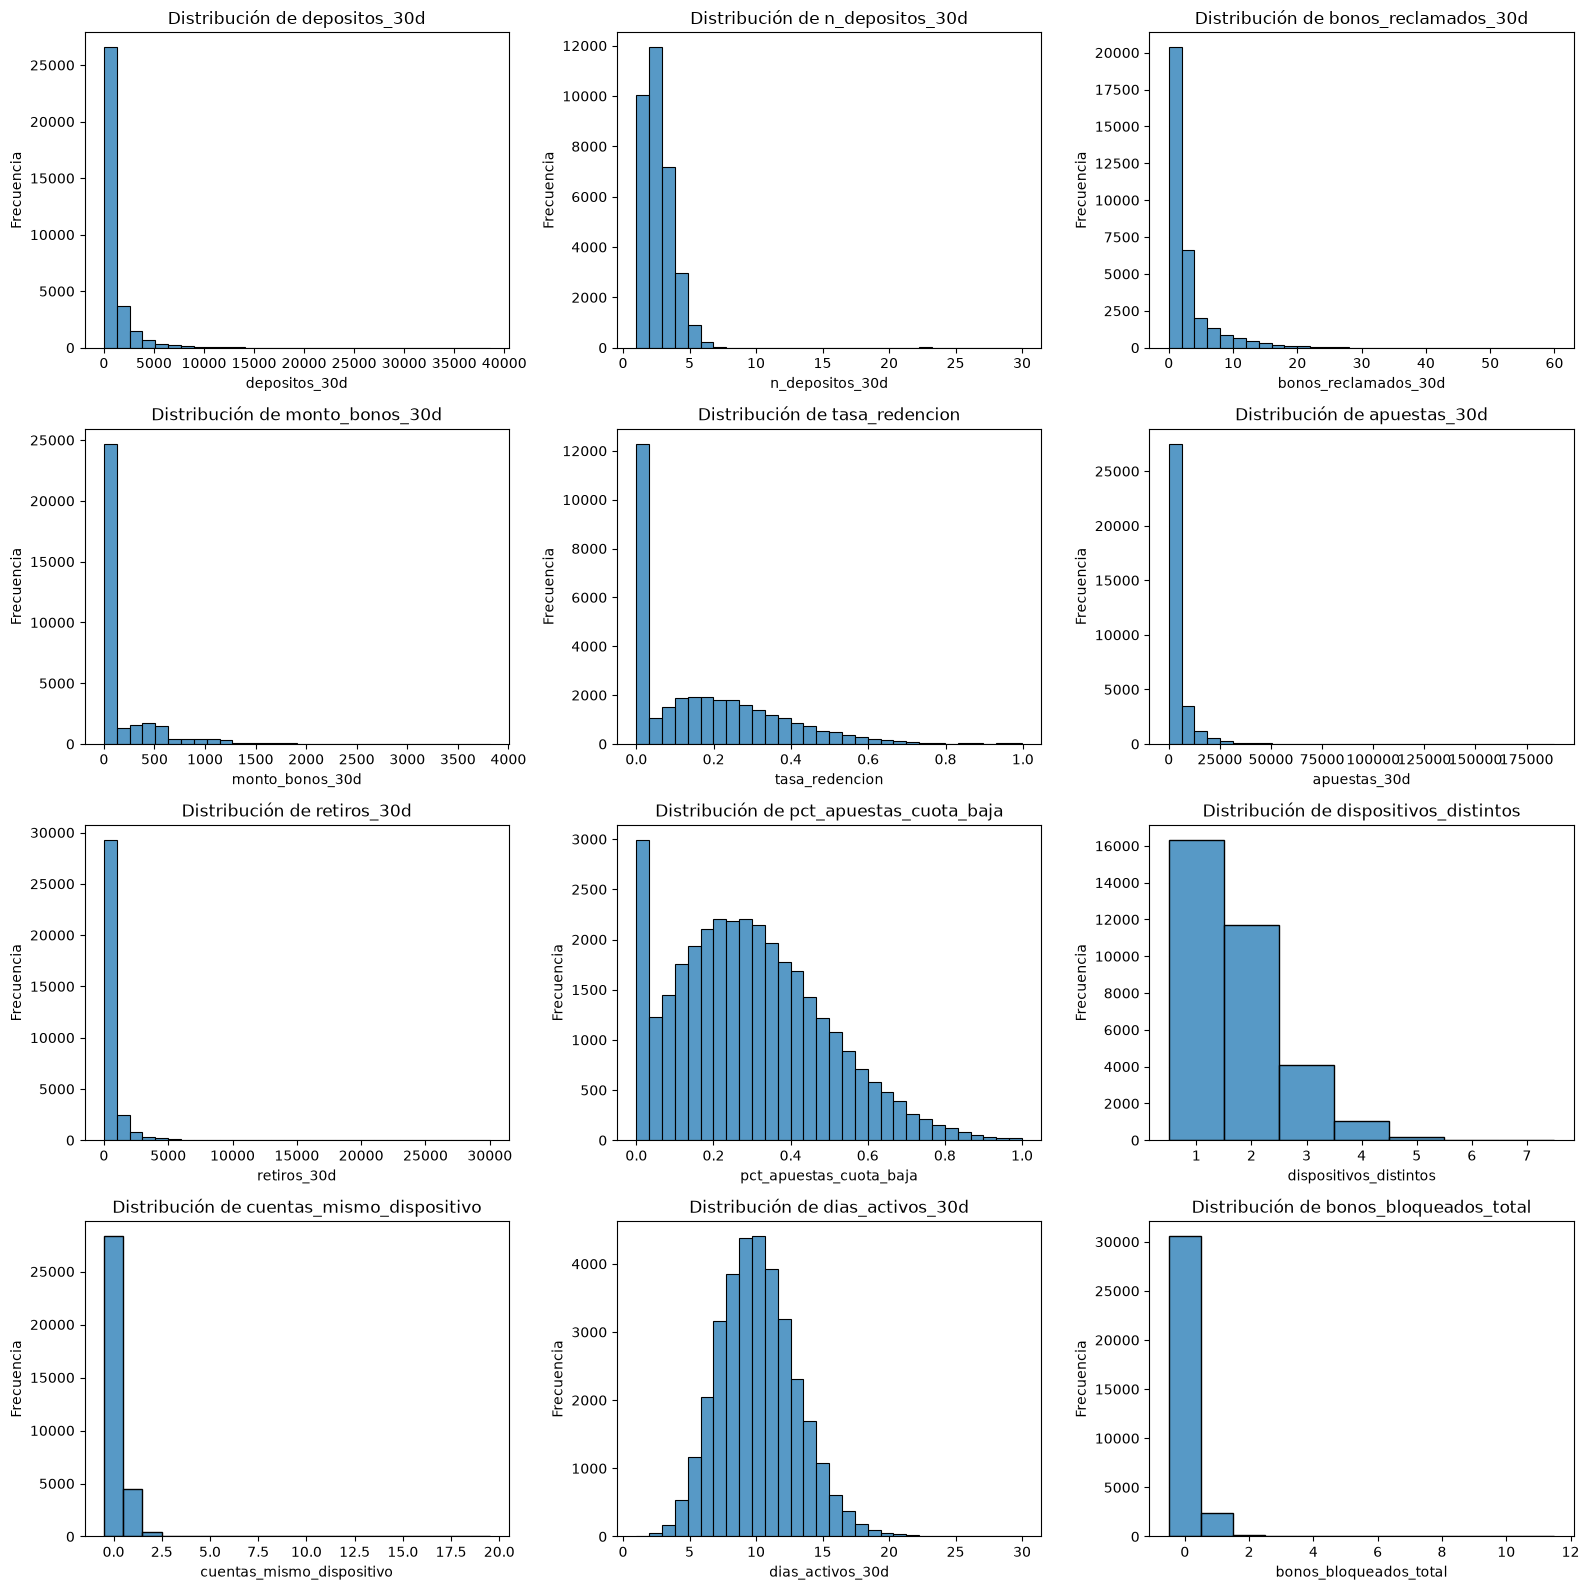

In [51]:
# Identificar columnas numéricas
numeric_cols = abuso_bonos_df.select_dtypes(
    include="number"
).columns.tolist()

# Excluir identificador y variable objetivo
exclude_cols = ["usuario_id", "marcado_abuso"]

numeric_features = [
    col for col in numeric_cols
    if col not in exclude_cols
]

# Configuración de los gráficos
n_cols = 3
n_rows = math.ceil(len(numeric_features) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 4 * n_rows)
)

axes = np.array(axes).flatten()

# Crear histogramas
for i, col in enumerate(numeric_features):

    data = abuso_bonos_df[col].dropna()

    if data.nunique() <= 12:
        sns.histplot(
            data=data,
            discrete=True,
            ax=axes[i]
        )
    else:
        sns.histplot(
            data=data,
            bins=30,
            ax=axes[i]
        )

    axes[i].set_title(f"Distribución de {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frecuencia")

# Eliminar espacios vacíos
for i in range(len(numeric_features), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

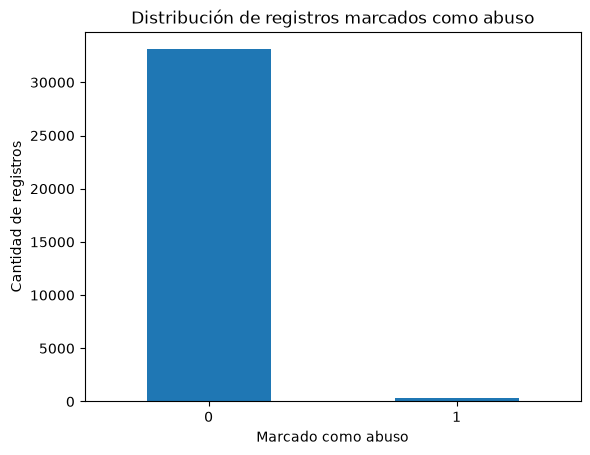

In [52]:
abuso_bonos_df["marcado_abuso"].value_counts(
    dropna=False
).sort_index().plot(kind="bar")

plt.title("Distribución de registros marcados como abuso")
plt.xlabel("Marcado como abuso")
plt.ylabel("Cantidad de registros")
plt.xticks(rotation=0)
plt.show()

La distribución de `marcado_abuso` muestra un desbalance importante entre las clases.

Sin embargo, estos valores no representan la prevalencia real del abuso en toda la población, debido a que los registros no revisados también aparecen con valor cero. Por esta razón, será necesario analizar la relación entre la existencia de una revisión y el resultado registrado antes de construir los conjuntos de entrenamiento.


In [53]:
# Relación entre haber sido revisado y el resultado
revision_target = pd.crosstab(
    abuso_bonos_df["fecha_revision"].notna(), # False = NaN, True = date
    abuso_bonos_df["marcado_abuso"],
    margins=True
)

display(revision_target)

marcado_abuso,0,1,All
fecha_revision,,,
False,30418,0,30418
True,2667,294,2961
All,33085,294,33379


### Identificación de etiquetas no confirmadas

Al cruzar `fecha_revision` con `marcado_abuso`, encontramos que existen 30.418 registros sin revisión y 2.961 registros revisados.

Los registros no revisados tienen `marcado_abuso = 0`, pero no podemos interpretarlos como verdaderos negativos, ya que no existe una revisión que confirme ese resultado.

Incluirlos directamente como negativos en un modelo supervisado introduciría ruido en las etiquetas.

Por esta razón, decidimos utilizar únicamente las observaciones que cuentan con una fecha de revisión registrada. De esta manera, el modelo aprenderá a partir de resultados observados por el equipo de Riesgo.

Esta decisión introduce una limitación: los usuarios revisados históricamente pueden no representar aleatoriamente a toda la población.


In [54]:
# Identificar usuarios que cumplen la regla actual
abuso_bonos_df["regla_actual"] = (
    abuso_bonos_df["bonos_reclamados_30d"] >= 3
)

# Comparar la regla actual con las revisiones realizadas
revision_regla = pd.crosstab(
    abuso_bonos_df["regla_actual"],
    abuso_bonos_df["fecha_revision"].notna(),
    margins=True
)

display(revision_regla)

fecha_revision,False,True,All
regla_actual,,,
False,23120,1794,24914
True,7298,1167,8465
All,30418,2961,33379


### Análisis del criterio de selección actual

La regla vigente establece que un usuario debe ser revisado cuando reclama tres o más bonos durante los últimos 30 días.

Analizamos la relación entre este criterio y la existencia de una revisión histórica para conocer cómo se distribuyeron las revisiones realizadas por Riesgo.

Encontramos que, de los 8.465 registros que cumplían la regla, solamente 1.167 fueron revisados. Por otra parte, 1.794 usuarios que no cumplían el criterio también fueron revisados.

Esto indica que la regla está relacionada con la selección histórica, pero no explica por completo las decisiones de revisión del equipo.


In [55]:
# Analizar únicamente los registros revisados
revisados = abuso_bonos_df[
    abuso_bonos_df["fecha_revision"].notna()
]

resultado_regla = pd.crosstab(
    revisados["regla_actual"],
    revisados["marcado_abuso"],
    margins=True
)

display(resultado_regla)

marcado_abuso,0,1,All
regla_actual,,,
False,1684,110,1794
True,983,184,1167
All,2667,294,2961



### Capacidad de detección de la regla actual

Para evitar conclusiones derivadas de etiquetas desconocidas, evaluamos la regla únicamente sobre los registros que efectivamente fueron revisados.

Entre los usuarios revisados que cumplían la regla, 184 de 1.167 (15,77 %) fueron identificados como abusadores.

De los 294 abusadores identificados, 184 (62,59 %) cumplían la regla actual, mientras que 110 (37,41 %) no cumplían este criterio.

Estos resultados sugieren que la regla consigue identificar una parte de los abusadores observados, pero deja por fuera otros casos que podrían presentar comportamientos de riesgo.

Los porcentajes corresponden exclusivamente a la población revisada y no representan el desempeño de la regla sobre todos los usuarios.


In [56]:
moneda = pd.crosstab(
    abuso_bonos_df["moneda"],
    abuso_bonos_df["marca"],
    margins=True
)

display(moneda)

marca,A,B,All
moneda,,,
HNL,0,13443,13443
USD,19936,0,19936
All,19936,13443,33379


In [57]:
marca = pd.crosstab(
    abuso_bonos_df["moneda"],
    abuso_bonos_df["marcado_abuso"],
    margins=True
)

display(marca)

marcado_abuso,0,1,All
moneda,,,
HNL,13287,156,13443
USD,19798,138,19936
All,33085,294,33379


### Diferencias entre marcas y monedas

Al analizar la correspondencia entre marca y moneda, encontramos que:

- La marca A reporta sus montos en USD.
- La marca B reporta sus montos en HNL.

Esta correspondencia permite trabajar con modelos independientes para cada marca, evitando mezclar variables monetarias expresadas en unidades diferentes.

Los resultados económicos se calcularán inicialmente en la moneda correspondiente a cada marca y posteriormente se consolidarán en USD.


In [58]:
abusos_agosto = pd.crosstab(
    abuso_bonos_df["fecha_revision"].notna(),
    abuso_bonos_df["fecha_corte"] == '2026-08-31',
    margins=True,
    rownames=['revisado'],
    colnames=['fecha_corte=2026-08-31']
)

display(abusos_agosto)

fecha_corte=2026-08-31,False,True,All
revisado,,,
False,25932,4486,30418
True,2636,325,2961
All,28568,4811,33379



### Tratamiento de las revisiones y madurez de las etiquetas

La fecha de extracción del conjunto de datos es el 6 de octubre de 2026. Según el diccionario de datos, una revisión puede producirse hasta 60 días después del corte mensual.

Por tanto, los cortes de agosto y septiembre todavía no habían completado su ventana de seguimiento al momento de la extracción:

- Agosto: seguimiento hasta el 30 de octubre de 2026.
- Septiembre: seguimiento hasta el 29 de noviembre de 2026.

En agosto se identifican 325 registros revisados. Decidimos conservar los registros que ya cuentan con una revisión efectiva y utilizar su resultado observado por el equipo de Riesgo.

Los registros sin revisión se excluyen del entrenamiento porque no cuentan con una etiqueta confirmada.

Esta decisión permite aprovechar la información disponible, aunque implica que las etiquetas de los últimos meses representan una observación parcial.


## Separación de datos por marca
Separamos los registros en dos conjuntos independientes, correspondientes a las marcas A y B.

Adicionalmente, conservamos únicamente los registros que cuentan con una fecha de revisión válida. De esta manera, evitamos utilizar observaciones sin una etiqueta confirmada.

Los dos conjuntos mantienen sus unidades monetarias originales: USD para la marca A y HNL para la marca B.


In [59]:
# Separar los datos por marca, y nos quedamos con los revisados
marca_a_df = abuso_bonos_df[(
    (abuso_bonos_df["marca"] == "A") & 
    abuso_bonos_df['fecha_revision'].notna()
)].copy()

marca_b_df = abuso_bonos_df[(
    (abuso_bonos_df["marca"] == "B") &
    abuso_bonos_df['fecha_revision'].notna()
)].copy()


### Selección de características y variable objetivo

Seleccionamos 11 características numéricas relacionadas con el comportamiento de los usuarios durante los últimos 30 días.

Estas variables contienen información sobre depósitos, bonos reclamados, apuestas, retiros, redención de bonos, dispositivos utilizados y actividad de los usuarios.

Definimos `marcado_abuso` como nuestra variable objetivo:

- 1: usuario identificado como abusador por Riesgo.
- 0: usuario revisado en el que Riesgo no identificó abuso.

Excluimos identificadores, variables asociadas al proceso de revisión y columnas que podrían introducir fuga de información.

En particular, excluimos `bonos_bloqueados_total` porque representa un histórico calculado a la fecha de extracción y podría incorporar información posterior al corte mensual.

La selección busca utilizar información de comportamiento disponible antes de realizar una revisión.


In [60]:
feature_cols = [
    "depositos_30d",
    "n_depositos_30d",
    "bonos_reclamados_30d",
    "monto_bonos_30d",
    "tasa_redencion",
    "apuestas_30d",
    "retiros_30d",
    "pct_apuestas_cuota_baja",
    "dispositivos_distintos",
    "cuentas_mismo_dispositivo",
    "dias_activos_30d"
]

target_col = "marcado_abuso"


## Separación de conjuntos de entrenamiento y prueba (Train/Test Split)

Dividimos cada conjunto por marca en entrenamiento (80 %) y prueba (20 %), utilizando `GroupShuffleSplit`.

La separación se realiza agrupando por `usuario_id`, debido a que un mismo usuario puede aparecer en diferentes cortes mensuales.

Esta estrategia evita que registros del mismo usuario aparezcan simultáneamente en entrenamiento y prueba, reduciendo el riesgo de fuga de información.

El conjunto de prueba se reserva para la evaluación final y no se utilizará durante el entrenamiento ni la selección de modelos.


In [61]:
def split_por_usuario(df, test_size=0.2, random_state=42):

    X = df[feature_cols]
    y = df[target_col]
    groups = df["usuario_id"]

    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=test_size,
        random_state=random_state
    )

    train_idx, test_idx = next(
        splitter.split(X, y, groups=groups)
    )

    X_train = X.iloc[train_idx].copy()
    X_test = X.iloc[test_idx].copy()

    y_train = y.iloc[train_idx].copy()
    y_test = y.iloc[test_idx].copy()

    return X_train, X_test, y_train, y_test

In [62]:
# Marca A
X_a_train, X_a_test, y_a_train, y_a_test = (
    split_por_usuario(marca_a_df)
)

# Marca B
X_b_train, X_b_test, y_b_train, y_b_test = (
    split_por_usuario(marca_b_df)
)

In [63]:
def mostrar_distribucion(marca, y_train, y_test):

    print(f"\n{'=' * 45}")
    print(f"DISTRIBUCIÓN DE CLASES - MARCA {marca}")
    print(f"{'=' * 45}")

    for nombre, y in [
        ("Entrenamiento", y_train),
        ("Prueba", y_test)
    ]:
        valores = y.value_counts()
        porcentajes = y.value_counts(normalize=True) * 100

        print(f"\nConjunto de {nombre} (n={len(y)})")
        print(f"  No abuso (0): {valores[0]} ({porcentajes[0]:.2f}%)")
        print(f"  Abuso (1):    {valores[1]} ({porcentajes[1]:.2f}%)")


mostrar_distribucion("A", y_a_train, y_a_test)
mostrar_distribucion("B", y_b_train, y_b_test)


DISTRIBUCIÓN DE CLASES - MARCA A

Conjunto de Entrenamiento (n=1395)
  No abuso (0): 1290 (92.47%)
  Abuso (1):    105 (7.53%)

Conjunto de Prueba (n=355)
  No abuso (0): 322 (90.70%)
  Abuso (1):    33 (9.30%)

DISTRIBUCIÓN DE CLASES - MARCA B

Conjunto de Entrenamiento (n=959)
  No abuso (0): 832 (86.76%)
  Abuso (1):    127 (13.24%)

Conjunto de Prueba (n=252)
  No abuso (0): 223 (88.49%)
  Abuso (1):    29 (11.51%)



### Distribución de clases en los conjuntos separados

Comprobamos la proporción de usuarios marcados como abusadores y no abusadores en los conjuntos de entrenamiento y prueba.

Los resultados muestran distribuciones relativamente cercanas:

- Marca A: 7,53 % de positivos en entrenamiento y 9,30 % en prueba.
- Marca B: 13,24 % de positivos en entrenamiento y 11,51 % en prueba.

Aunque `GroupShuffleSplit` no realiza una estratificación explícita, las proporciones obtenidas permiten continuar con la experimentación.

Debido al número reducido de positivos, tendremos que interpretar las métricas de evaluación con cautela.



## Construcción de modelos de clasificación

Para identificar una estrategia adecuada de priorización de revisiones, experimentamos con cuatro algoritmos:

1. **Regresión logística:** modelo lineal que permite interpretar la relación entre las características y la clasificación.
2. **Árbol de decisión:** permite identificar reglas de decisión y relaciones no lineales.
3. **Linear SVC:** clasificador basado en máquinas de soporte vectorial que busca encontrar una frontera de separación entre las clases maximizando el margen.
4. **Random Forest:** modelo de ensamble que combina múltiples árboles de decisión para capturar patrones e interacciones entre características.

Cada algoritmo se encapsula en un pipeline para organizar el preprocesamiento y el entrenamiento.

La regresión logística y Linear SVC utilizan `StandardScaler` porque son sensibles a las escalas de las características. Los modelos basados en árboles no requieren estandarización.

Utilizamos configuraciones iniciales de hiperparámetros y no realizamos una búsqueda exhaustiva debido al tiempo disponible para desarrollar la prueba.


In [64]:
# Pipeline de regresión logística
logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

In [65]:
# Pipeline de árbol de decisión
tree_pipeline = Pipeline([
    ("classifier", DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=20,
        random_state=42,
        class_weight='balanced'
    ))
])

In [66]:
# Pipeline de Linear Support Vector Machine Classifier
svc_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LinearSVC(
        C=1.0,
        class_weight="balanced",
        max_iter=10000,
        random_state=42
    ))
])

In [67]:
# Pipeline de Random Forest
rf_pipeline = Pipeline([
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=6,
        min_samples_leaf=10,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

## Separación de entrenamiento y validación
Separamos una parte del conjunto de entrenamiento para evaluar y comparar los modelos, evitando utilizar el conjunto de prueba durante la selección de modelos y umbrales. La separación se realiza agrupando por usuario para evitar contaminación entre conjuntos.

In [68]:
def crear_split_validacion(X_train, y_train, df_marca):

    groups = df_marca.loc[X_train.index, "usuario_id"]

    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.20,
        random_state=42
    )

    train_idx, val_idx = next(
        splitter.split(X_train, y_train, groups=groups)
    )

    return (
        X_train.iloc[train_idx],
        X_train.iloc[val_idx],
        y_train.iloc[train_idx],
        y_train.iloc[val_idx]
    )

In [69]:
# Marca A
X_a_fit, X_a_val, y_a_fit, y_a_val = (
    crear_split_validacion(
        X_a_train, y_a_train, marca_a_df
    )
)

# Marca B
X_b_fit, X_b_val, y_b_fit, y_b_val = (
    crear_split_validacion(
        X_b_train, y_b_train, marca_b_df
    )
)


### Inicialización de modelos independientes

Creamos instancias independientes de cada pipeline utilizando `clone()`.

Esto permite mantener separados los estimadores de cada marca, evitando compartir parámetros aprendidos durante el entrenamiento.

Posteriormente, entrenamos los cuatro algoritmos para cada marca utilizando únicamente los subconjuntos de ajuste correspondientes.


In [70]:
# Crear modelos independientes para cada marca

models = {
    "A": {
        "Logistic Regression": clone(logistic_pipeline),
        "Decision Tree": clone(tree_pipeline),
        "Linear SVC": clone(svc_pipeline),
        "Random Forest": clone(rf_pipeline)
    },

    "B": {
        "Logistic Regression": clone(logistic_pipeline),
        "Decision Tree": clone(tree_pipeline),
        "Linear SVC": clone(svc_pipeline),
        "Random Forest": clone(rf_pipeline)
    }
}

In [71]:
# Datos de entrenamiento para cada marca
train_data = {
    "A": (X_a_fit, y_a_fit),
    "B": (X_b_fit, y_b_fit)
}

for marca, modelos in models.items():

    X_fit, y_fit = train_data[marca]

    for nombre, modelo in modelos.items():

        modelo.fit(X_fit, y_fit)

        print(f"Marca {marca} - {nombre}: entrenado")

Marca A - Logistic Regression: entrenado
Marca A - Decision Tree: entrenado
Marca A - Linear SVC: entrenado
Marca A - Random Forest: entrenado
Marca B - Logistic Regression: entrenado
Marca B - Decision Tree: entrenado
Marca B - Linear SVC: entrenado
Marca B - Random Forest: entrenado



### Evaluación del desempeño predictivo

Evaluamos los modelos mediante las siguientes métricas:

- **Precision:** proporción de usuarios identificados como abusadores que efectivamente fueron marcados por Riesgo.
- **Recall:** proporción de abusadores identificados por Riesgo que fueron detectados por el modelo.
- **F1-score:** media armónica entre precision y recall.
- **Average Precision:** resume el desempeño de la relación precision-recall a diferentes umbrales, siendo útil para problemas con clases desbalanceadas.

También utilizamos matrices de confusión para identificar:

- TN: usuarios no abusadores correctamente clasificados.
- FP: usuarios no abusadores seleccionados para revisión.
- FN: abusadores que el modelo no detectó.
- TP: abusadores correctamente identificados.

Debido al objetivo del problema, prestamos especial atención al recall, sin dejar de considerar la precision y el desempeño general de los modelos.


In [72]:
def evaluar_modelo(modelo, X_val, y_val, nombre):

    y_pred = modelo.predict(X_val)

    # Obtener puntuaciones para evaluar el ranking
    if hasattr(modelo, "predict_proba"):
        y_scores = modelo.predict_proba(X_val)[:, 1]
    else:
        y_scores = modelo.decision_function(X_val)

    print(f"\n{nombre}")
    print("-" * 40)

    print(f"Precision: {precision_score(y_val, y_pred, zero_division=0):.4f}")
    print(f"Recall:    {recall_score(y_val, y_pred, zero_division=0):.4f}")
    print(f"F1-score:  {f1_score(y_val, y_pred, zero_division=0):.4f}")
    print(f"Average Precision: {average_precision_score(y_val, y_scores):.4f}")

    print("\nMatriz de confusión:")
    print(confusion_matrix(y_val, y_pred, labels=[0, 1]))

In [73]:
for marca in ["A", "B"]:

    X_val = X_a_val if marca == "A" else X_b_val
    y_val = y_a_val if marca == "A" else y_b_val

    for nombre, modelo in models[marca].items():

        evaluar_modelo(
            modelo,
            X_val,
            y_val,
            f"Marca {marca} - {nombre}"
        )


Marca A - Logistic Regression
----------------------------------------
Precision: 0.6667
Recall:    0.3200
F1-score:  0.4324
Average Precision: 0.5064

Matriz de confusión:
[[254   4]
 [ 17   8]]

Marca A - Decision Tree
----------------------------------------
Precision: 0.1910
Recall:    0.6800
F1-score:  0.2982
Average Precision: 0.3176

Matriz de confusión:
[[186  72]
 [  8  17]]

Marca A - Linear SVC
----------------------------------------
Precision: 0.3036
Recall:    0.6800
F1-score:  0.4198
Average Precision: 0.5655

Matriz de confusión:
[[219  39]
 [  8  17]]

Marca A - Random Forest
----------------------------------------
Precision: 0.3571
Recall:    0.4000
F1-score:  0.3774
Average Precision: 0.3325

Matriz de confusión:
[[240  18]
 [ 15  10]]

Marca B - Logistic Regression
----------------------------------------
Precision: 0.7000
Recall:    0.3043
F1-score:  0.4242
Average Precision: 0.6293

Matriz de confusión:
[[171   3]
 [ 16   7]]

Marca B - Decision Tree
-----------


### Resultados de la comparación de modelos

Los resultados muestran diferencias entre los algoritmos y las dos marcas.

En la marca A, Linear SVC obtiene el mayor Average Precision (0,5655), con un recall de 0,68.

En la marca B, la regresión logística obtiene un Average Precision de 0,6293, ligeramente superior al 0,6126 de Linear SVC. Sin embargo, Linear SVC alcanza un recall de 0,8696 y un F1-score de 0,5128.

Considerando la prioridad de identificar abusadores y los resultados posteriores de evaluación económica, seleccionamos Linear SVC como candidato para ambas marcas.

Esta selección no implica que sea superior en todas las métricas, sino que ofrece resultados adecuados para continuar con la evaluación económica.



### Línea base: regla actual de Riesgo

Utilizamos la regla vigente de tres o más bonos reclamados durante los últimos 30 días como estrategia de referencia.

Aplicamos el mismo criterio sobre los conjuntos de validación y comparamos sus matrices de confusión con las obtenidas por los modelos.

Esto permite identificar cuántos abusadores detecta la estrategia actual y cuántos usuarios adicionales envía a revisión sin haber sido identificados como abusadores.

Todas las comparaciones se realizan sobre las mismas observaciones revisadas.


In [74]:
# Regla actual: tres o más bonos
y_a_regla = (X_a_val["bonos_reclamados_30d"] >= 3).astype(int)
y_b_regla = (X_b_val["bonos_reclamados_30d"] >= 3).astype(int)

print("MARCA A - REGLA ACTUAL")
print(confusion_matrix(y_a_val, y_a_regla, labels=[0, 1]))

print("\nMARCA B - REGLA ACTUAL")
print(confusion_matrix(y_b_val, y_b_regla, labels=[0, 1]))

MARCA A - REGLA ACTUAL
[[196  62]
 [ 13  12]]

MARCA B - REGLA ACTUAL
[[ 66 108]
 [  4  19]]



## Configuración de los supuestos económicos

Según el enunciado, cada revisión realizada por el equipo de Riesgo tiene un coste de USD 4.

Como las marcas trabajan con monedas diferentes, mantenemos los cálculos económicos separados:

- Marca A: USD.
- Marca B: HNL.

Definimos un tipo de cambio de referencia de 26,89 HNL por USD para convertir los resultados de la marca B y consolidar los beneficios.

Este tipo de cambio se utiliza como un supuesto fijo para simplificar los cálculos de la prueba.


In [75]:
# Configuración económica global

HNL_PER_USD = 26.89  # Lempiras por dólar

USD_PER_HNL = 1 / HNL_PER_USD

REVIEW_COST_USD = 4
REVIEW_COST_HNL = REVIEW_COST_USD * HNL_PER_USD


### Selección del umbral y evaluación del beneficio económico

El modelo Linear SVC genera una puntuación de decisión (*decision score*) para cada usuario. Esta puntuación permite establecer un umbral de clasificación, a partir del cual decidimos qué usuarios serán candidatos a revisión.

Un usuario se clasifica como positivo cuando su puntuación es mayor o igual al umbral establecido.

La selección del umbral es importante porque modifica la cantidad de usuarios enviados a revisión, afectando tanto la detección de abusadores como los costes operativos.

Para seleccionar el umbral utilizamos el beneficio económico estimado, definido como:

**Beneficio neto = Bonos protegidos - Coste de revisiones**

Donde:
- **Bonos protegidos:** suma de los montos de bonos reclamados por los usuarios identificados como abusadores (TP).
- **Coste de revisiones:** número total de usuarios seleccionados multiplicado por el coste de cada revisión.

Los cálculos se realizan en la moneda de cada marca. Posteriormente, los resultados se pueden consolidar en USD utilizando el tipo de cambio definido.

Finalmente, seleccionamos el umbral que maximiza el beneficio neto observado en el conjunto de validación.


In [76]:
def evaluar_umbral_svc(
    modelo,
    X_val,
    y_val,
    df_marca,
    marca
):
    # Obtener puntuaciones del SVC
    scores = pd.Series(
        modelo.decision_function(X_val),
        index=X_val.index
    )

    # Recuperar montos de bonos correspondientes
    montos = df_marca.loc[
        X_val.index, "monto_bonos_30d"
    ]

    # Definir coste por revisión según la moneda
    if marca == "A":
        costo_revision = REVIEW_COST_USD
        moneda = "USD"
    else:
        costo_revision = REVIEW_COST_HNL
        moneda = "HNL"

    # Umbrales candidatos
    umbrales = np.r_[
        np.inf,
        np.sort(scores.unique())[::-1]
    ]

    resultados = []

    for umbral in umbrales:

        pred = scores >= umbral

        tp = pred & y_val.eq(1)
        fp = pred & y_val.eq(0)
        fn = ~pred & y_val.eq(1)

        revisiones = int(pred.sum())

        bonos_protegidos = montos[tp].sum()
        costo_total = revisiones * costo_revision

        beneficio_neto = bonos_protegidos - costo_total

        resultados.append({
            "umbral": umbral,
            "revisiones": revisiones,
            "TP": int(tp.sum()),
            "FP": int(fp.sum()),
            "FN": int(fn.sum()),
            "bonos_protegidos": bonos_protegidos,
            "costo_revision": costo_total,
            "beneficio_neto": beneficio_neto,
            "moneda": moneda
        })

    resultados_df = pd.DataFrame(resultados)

    return resultados_df.sort_values(
        "beneficio_neto",
        ascending=False
    ).reset_index(drop=True)

In [77]:
resultados_a = evaluar_umbral_svc(
    models["A"]["Linear SVC"],
    X_a_val,
    y_a_val,
    marca_a_df,
    "A"
)

resultados_b = evaluar_umbral_svc(
    models["B"]["Linear SVC"],
    X_b_val,
    y_b_val,
    marca_b_df,
    "B"
)

In [78]:
print("MARCA A - BENEFICIO EN USD")
display(resultados_a.head(10).round(2))

print("MARCA B - BENEFICIO EN HNL")
display(resultados_b.head(10).round(2))

MARCA A - BENEFICIO EN USD


,umbral,revisiones,TP,FP,FN,bonos_protegidos,costo_revision,beneficio_neto,moneda
0,0.26,36,16,20,9,608.90,144,464.90,USD
1,0.25,37,16,21,9,608.90,148,460.90,USD
2,0.23,38,16,22,9,608.90,152,456.90,USD
3,0.26,33,15,18,10,588.34,132,456.34,USD
4,0.22,39,16,23,9,608.90,156,452.90,USD
5,0.26,34,15,19,10,588.34,136,452.34,USD
6,0.21,40,16,24,9,608.90,160,448.90,USD
7,0.26,35,15,20,10,588.34,140,448.34,USD
8,0.21,41,16,25,9,608.90,164,444.90,USD
9,0.19,42,16,26,9,608.90,168,440.90,USD


MARCA B - BENEFICIO EN HNL


,umbral,revisiones,TP,FP,FN,bonos_protegidos,costo_revision,beneficio_neto,moneda
0,-0.11,66,21,45,2,24820.95,7098.96,17721.99,HNL
1,-0.12,67,21,46,2,24820.95,7206.52,17614.43,HNL
2,-0.12,68,21,47,2,24820.95,7314.08,17506.87,HNL
3,-0.17,69,21,48,2,24820.95,7421.64,17399.31,HNL
4,-0.17,70,21,49,2,24820.95,7529.20,17291.75,HNL
5,-0.17,71,21,50,2,24820.95,7636.76,17184.19,HNL
6,-0.21,78,22,56,1,25540.23,8389.68,17150.55,HNL
7,-0.18,72,21,51,2,24820.95,7744.32,17076.63,HNL
8,-0.22,79,22,57,1,25540.23,8497.24,17042.99,HNL
9,-0.19,73,21,52,2,24820.95,7851.88,16969.07,HNL



### Resultados de la selección de umbrales

La evaluación económica permite identificar el umbral que maximiza el beneficio neto observado en validación para cada marca.

En la marca A, el mejor resultado corresponde a un umbral aproximado de 0,26. Con este criterio se seleccionan 36 usuarios, de los cuales 16 fueron identificados como abusadores. El beneficio neto observado es de USD 464,90.

En la marca B, el mejor resultado corresponde a un umbral aproximado de -0,11. Se seleccionan 66 usuarios, de los cuales 21 fueron identificados como abusadores. El beneficio neto observado es de 17.721,99 HNL.

Los umbrales son diferentes porque los modelos fueron entrenados de manera independiente.

Los valores mostrados en las tablas están redondeados; los cálculos utilizan los valores completos.



### Evaluación económica de la regla actual

Para comparar ambas estrategias bajo las mismas condiciones, calculamos el beneficio neto de la regla actual sobre los mismos conjuntos de validación.

Utilizamos la misma definición económica aplicada al modelo:

**Beneficio neto = Bonos protegidos - Coste de revisiones**

Así obtenemos una línea base económica que permite cuantificar el beneficio incremental de nuestra propuesta.


In [79]:
def evaluar_regla_actual(
    X_val,
    y_val,
    df_marca,
    marca
):
    montos = df_marca.loc[
        X_val.index, "monto_bonos_30d"
    ]

    # Regla actual
    pred = X_val["bonos_reclamados_30d"] >= 3

    tp = pred & y_val.eq(1)
    fp = pred & y_val.eq(0)
    fn = ~pred & y_val.eq(1)

    revisiones = int(pred.sum())

    bonos_protegidos = montos[tp].sum()

    costo_revision = (
        REVIEW_COST_USD if marca == "A"
        else REVIEW_COST_HNL
    )

    costo_total = revisiones * costo_revision

    return {
        "revisiones": revisiones,
        "TP": int(tp.sum()),
        "FP": int(fp.sum()),
        "FN": int(fn.sum()),
        "bonos_protegidos": bonos_protegidos,
        "costo_revision": costo_total,
        "beneficio_neto": bonos_protegidos - costo_total
    }

In [80]:
regla_a = evaluar_regla_actual(
    X_a_val, y_a_val, marca_a_df, "A"
)

regla_b = evaluar_regla_actual(
    X_b_val, y_b_val, marca_b_df, "B"
)

In [81]:
comparacion = pd.DataFrame([
    {
        "marca": "A",
        "estrategia": "Regla actual",
        **regla_a
    },
    {
        "marca": "A",
        "estrategia": "Linear SVC",
        **resultados_a.iloc[0].to_dict()
    },
    {
        "marca": "B",
        "estrategia": "Regla actual",
        **regla_b
    },
    {
        "marca": "B",
        "estrategia": "Linear SVC",
        **resultados_b.iloc[0].to_dict()
    }
])

display(comparacion.round(2))

,marca,estrategia,revisiones,TP,FP,FN,bonos_protegidos,costo_revision,beneficio_neto,umbral,moneda
0,A,Regla actual,74,12,62,13,571.25,296.00,275.25,NaN,NaN
1,A,Linear SVC,36,16,20,9,608.90,144.00,464.90,0.26,USD
2,B,Regla actual,127,19,108,4,22919.85,13660.12,9259.73,NaN,NaN
3,B,Linear SVC,66,21,45,2,24820.95,7098.96,17721.99,-0.11,HNL


In [82]:
ahorro_a = (
    resultados_a.iloc[0]["beneficio_neto"]
    - regla_a["beneficio_neto"]
)

ahorro_b = (
    resultados_b.iloc[0]["beneficio_neto"]
    - regla_b["beneficio_neto"]
)

ahorro_total_usd = (
    ahorro_a + ahorro_b * USD_PER_HNL
)

print(f"Ahorro incremental Marca A: {ahorro_a:,.2f} USD")
print(f"Ahorro incremental Marca B: {ahorro_b:,.2f} HNL")
print(f"Ahorro incremental consolidado: {ahorro_total_usd:,.2f} USD")

Ahorro incremental Marca A: 189.65 USD
Ahorro incremental Marca B: 8,462.26 HNL
Ahorro incremental consolidado: 504.35 USD



### Comparación económica en validación

En la marca A, Linear SVC obtiene un beneficio neto de USD 464,90, frente a USD 275,25 de la regla actual. La diferencia es de USD 189,65.

En la marca B, el modelo obtiene un beneficio neto de 17.721,99 HNL, frente a 9.259,73 HNL de la regla actual. La diferencia es de 8.462,26 HNL.

Al consolidar ambos resultados utilizando el tipo de cambio definido, obtenemos un beneficio incremental estimado de USD 504,35 en validación.

Estos resultados se utilizan para seleccionar la estrategia y los umbrales, pero no representan todavía el resultado de la evaluación final.



## Evaluación final sobre el conjunto de prueba

Una vez seleccionados los umbrales mediante validación, los mantenemos fijos para realizar la evaluación final.

Aplicamos las puntuaciones de decisión de los modelos Linear SVC sobre los conjuntos de prueba y clasificamos a los usuarios utilizando los umbrales seleccionados.

No realizamos nuevos ajustes utilizando los datos de prueba. De esta manera, reservamos este conjunto para evaluar el desempeño y el beneficio económico de las estrategias seleccionadas.


In [83]:
umbral_a = resultados_a.iloc[0]["umbral"]
umbral_b = resultados_b.iloc[0]["umbral"]

In [84]:
# Marca A
scores_a_test = models["A"]["Linear SVC"].decision_function(X_a_test)

pred_a_test = (
    scores_a_test >= umbral_a
).astype(int)


# Marca B
scores_b_test = models["B"]["Linear SVC"].decision_function(X_b_test)

pred_b_test = (
    scores_b_test >= umbral_b
).astype(int)


### Evaluación económica en test

Evaluamos las predicciones de Linear SVC y de la regla actual sobre los mismos registros del conjunto de prueba.

Para cada estrategia calculamos las revisiones realizadas, verdaderos positivos, falsos positivos, falsos negativos y verdaderos negativos.

También calculamos los bonos protegidos y el coste total de las revisiones para obtener el beneficio neto de cada alternativa.

El objetivo es determinar si la mejora observada durante la validación se mantiene en datos que no participaron en el entrenamiento ni en la selección del umbral.


In [85]:
def evaluar_test(X, y, df_marca, pred, marca, estrategia):

    pred = pd.Series(pred, index=X.index)
    montos = df_marca.loc[X.index, "monto_bonos_30d"]

    tp = (pred == 1) & (y == 1)
    fp = (pred == 1) & (y == 0)
    fn = (pred == 0) & (y == 1)
    tn = (pred == 0) & (y == 0)

    costo = REVIEW_COST_USD if marca == "A" else REVIEW_COST_HNL

    bonos_protegidos = montos[tp].sum()
    costo_total = int(pred.sum()) * costo

    return {
        "marca": marca,
        "estrategia": estrategia,
        "revisiones": int(pred.sum()),
        "TP": int(tp.sum()),
        "FP": int(fp.sum()),
        "FN": int(fn.sum()),
        "TN": int(tn.sum()),
        "bonos_protegidos": bonos_protegidos,
        "costo_revision": costo_total,
        "beneficio_neto": bonos_protegidos - costo_total
    }

In [86]:
# Predicciones de la regla actual
pred_a_regla_test = (
    X_a_test["bonos_reclamados_30d"] >= 3
).astype(int)

pred_b_regla_test = (
    X_b_test["bonos_reclamados_30d"] >= 3
).astype(int)


resultados_test = pd.DataFrame([
    evaluar_test(
        X_a_test, y_a_test, marca_a_df,
        pred_a_test, "A", "Linear SVC"
    ),
    evaluar_test(
        X_a_test, y_a_test, marca_a_df,
        pred_a_regla_test, "A", "Regla actual"
    ),
    evaluar_test(
        X_b_test, y_b_test, marca_b_df,
        pred_b_test, "B", "Linear SVC"
    ),
    evaluar_test(
        X_b_test, y_b_test, marca_b_df,
        pred_b_regla_test, "B", "Regla actual"
    )
])

display(resultados_test.round(2))

,marca,estrategia,revisiones,TP,FP,FN,TN,bonos_protegidos,costo_revision,beneficio_neto
0,A,Linear SVC,45,23,22,10,300,819.20,180.00,639.20
1,A,Regla actual,90,15,75,18,247,710.92,360.00,350.92
2,B,Linear SVC,81,24,57,5,166,23289.51,8712.36,14577.15
3,B,Regla actual,167,23,144,6,79,23348.33,17962.52,5385.81


In [87]:
test_a = resultados_test[
    resultados_test["marca"] == "A"
].set_index("estrategia")

test_b = resultados_test[
    resultados_test["marca"] == "B"
].set_index("estrategia")

ahorro_a_test = (
    test_a.loc["Linear SVC", "beneficio_neto"]
    - test_a.loc["Regla actual", "beneficio_neto"]
)

ahorro_b_test = (
    test_b.loc["Linear SVC", "beneficio_neto"]
    - test_b.loc["Regla actual", "beneficio_neto"]
)

ahorro_total_test_usd = (
    ahorro_a_test + ahorro_b_test * USD_PER_HNL
)

print(f"Marca A: {ahorro_a_test:,.2f} USD")
print(f"Marca B: {ahorro_b_test:,.2f} HNL")
print(f"Total consolidado: {ahorro_total_test_usd:,.2f} USD")

Marca A: 288.28 USD
Marca B: 9,191.34 HNL
Total consolidado: 630.09 USD



### Resultados de la evaluación final

Los resultados sobre el conjunto de prueba muestran que Linear SVC obtiene un beneficio neto superior al de la regla actual en ambas marcas.

**Marca A:**

- Linear SVC: 45 revisiones, 23 verdaderos positivos y beneficio neto de USD 639,20.
- Regla actual: 90 revisiones, 15 verdaderos positivos y beneficio neto de USD 350,92.

El beneficio incremental es de USD 288,28.

**Marca B:**

- Linear SVC: 81 revisiones, 24 verdaderos positivos y beneficio neto de 14.577,15 HNL.
- Regla actual: 167 revisiones, 23 verdaderos positivos y beneficio neto de 5.385,81 HNL.

El beneficio incremental es de 9.191,34 HNL.

Al consolidar ambos resultados mediante el tipo de cambio definido, obtenemos un beneficio incremental estimado de aproximadamente USD 630,09 en test.

Estos resultados corresponden exclusivamente a la muestra de prueba y no deben interpretarse como un ahorro mensual garantizado para toda la operación.



## Validación de la capacidad operativa

El equipo de Riesgo tiene una capacidad máxima de 600 revisiones mensuales, compartida entre ambas marcas.

Para verificar que nuestra propuesta respeta esta restricción, aplicamos los modelos y umbrales seleccionados sobre todos los registros disponibles, independientemente de si fueron revisados históricamente.

En esta etapa no utilizamos `marcado_abuso`, ya que el objetivo es estimar exclusivamente el volumen de usuarios que cada estrategia seleccionaría para revisión en cada corte mensual.

Comparamos los candidatos generados por Linear SVC frente a los seleccionados mediante la regla actual.


In [88]:
df_operativo = abuso_bonos_df.copy()

df_operativo["fecha_corte"] = pd.to_datetime(
    df_operativo["fecha_corte"]
)

df_operativo["seleccionado_svc"] = 0

for marca, umbral in [("A", umbral_a), ("B", umbral_b)]:

    mask = df_operativo["marca"] == marca

    X_operativo = df_operativo.loc[mask, feature_cols]

    scores = models[marca]["Linear SVC"].decision_function(
        X_operativo
    )

    df_operativo.loc[mask, "seleccionado_svc"] = (
        scores >= umbral
    ).astype(int)


# Comparar volumen mensual de ambas estrategias
df_operativo["seleccionado_regla"] = (
    df_operativo["bonos_reclamados_30d"] >= 3
).astype(int)

capacidad_mensual = df_operativo.groupby("fecha_corte").agg(
    candidatos_svc=("seleccionado_svc", "sum"),
    candidatos_regla=("seleccionado_regla", "sum")
)

capacidad_mensual["supera_600"] = (
    capacidad_mensual["candidatos_svc"] > 600
)

display(capacidad_mensual)

,candidatos_svc,candidatos_regla,supera_600
fecha_corte,,,
2026-01-31,153,178,False
2026-02-28,185,209,False
2026-03-31,257,247,False
2026-04-30,328,992,False
2026-05-31,403,1236,False
2026-06-30,479,1311,False
2026-07-31,473,1437,False
2026-08-31,477,1443,False
2026-09-30,455,1412,False



### Resultados de capacidad mensual

La estrategia basada en Linear SVC selecciona entre 153 y 479 usuarios por mes durante el periodo analizado, manteniéndose por debajo de la capacidad máxima de 600 revisiones.

En contraste, la regla actual supera esta capacidad a partir de abril de 2026, generando entre 992 y 1.443 candidatos mensuales.

Los resultados indican que los umbrales seleccionados permiten construir una estrategia compatible con la capacidad operativa disponible durante los nueve cortes analizados.

Esta comprobación mide el volumen de candidatos que produciría cada estrategia, no la cantidad de abusadores que serían efectivamente identificados.



## Conclusiones y recomendación para Riesgo

Se propone reemplazar la regla fija de tres o más bonos reclamados por una estrategia de clasificación basada en Linear SVC, utilizando modelos independientes para cada marca.

Los modelos permiten combinar diferentes características del comportamiento de los usuarios y seleccionar candidatos mediante umbrales ajustados a partir del beneficio económico observado en validación.

En la evaluación sobre test, la estrategia propuesta presenta un beneficio incremental consolidado estimado de USD 630,09 frente a la regla actual.

Adicionalmente, al aplicar los umbrales sobre todos los registros disponibles, la cantidad de candidatos seleccionados se mantiene por debajo de la capacidad máxima de 600 revisiones mensuales.

**Recomendación:** utilizar Linear SVC como una estrategia inicial de priorización de revisiones, manteniendo umbrales diferenciados por marca y realizando seguimiento periódico a sus resultados.

**Limitaciones:**

- El entrenamiento utiliza exclusivamente usuarios revisados, por lo que existe un posible sesgo de selección.
- Los resultados de test miden la capacidad de reproducir los abusos identificados históricamente por Riesgo, no necesariamente todos los abusos reales.
- Los últimos meses tienen ventanas de seguimiento incompletas.
- El beneficio consolidado depende del tipo de cambio de referencia utilizado.
- Se recomienda realizar revisiones aleatorias de usuarios no seleccionados por el modelo para obtener etiquetas adicionales y evaluar su capacidad de detección sobre una población más representativa.